In [13]:
#imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import matplotlib as mpl
import json
from pathlib import Path
from matplotlib.lines import Line2D


rc('text', usetex=True)
rc('text.latex', preamble=r'\usepackage{mathptmx}')

mpl.rcParams["text.usetex"] = True
mpl.rcParams["text.latex.preamble"] = r"""
    \usepackage[utf8]{inputenc}
    \usepackage{amssymb}
"""

PARAMETER_RTOL = 0.01

def within_one_percent(values, true_value, sigma):
    """Return True where an estimate is within 1% of its expected sigma."""
    values = np.asarray(values, dtype=float)
    true_value = np.asarray(true_value, dtype=float)
    sigma = np.asarray(sigma, dtype=float)
    return (
        np.isfinite(values)
        & np.isfinite(true_value)
        & np.isfinite(sigma)
        & (np.abs(values - true_value) <= PARAMETER_RTOL * sigma)
    )

def true_parameter_means(distribution, dimension):
    """Intrinsic-coordinate target means used by the benchmarks."""
    if distribution == 'Gaussian':
        return np.ones(dimension), 3.16 * np.ones(dimension)
    if distribution == 'Paired Rosenbrock':
        truth = np.empty(dimension)
        truth_sig = np.empty(dimension)
        truth[0::2] = 1.0
        truth[1::2] = 1.5
        truth_sig[0::2] = np.sqrt(0.5)
        truth_sig[1::2] = np.sqrt(2.505)
        return truth, truth_sig
    raise ValueError(f'Unknown distribution: {distribution}')

def majority_parameter_recovery_mask(root, folder_suffix, axis_values, sampler, distribution):
    """ESS mask: require a strict majority of parameter means to recover."""
    recovered = []
    for axis_value in axis_values:
        parameter_dir = Path(root) / f'{float(axis_value):g}{folder_suffix}'
        seed_means = []
        for summary_path in sorted(parameter_dir.glob('seeds/seed_*/results_summary.json')):
            result = json.loads(summary_path.read_text()).get('summary', {}).get(sampler)
            if result is not None:
                seed_means.append(np.asarray(result['parameter_mean'], dtype=float))

        if not seed_means:
            recovered.append(False)
            continue

        median_means = np.nanmedian(np.stack(seed_means), axis=0)
        truths, truth_sigs = true_parameter_means(distribution, median_means.size)
        parameter_recovered = within_one_percent(
            median_means, truths, truth_sigs
        )
        recovered.append(
            np.count_nonzero(parameter_recovered) > parameter_recovered.size / 2
        )

    return np.asarray(recovered, dtype=bool)

def single_parameter_recovery_mask(values, true_value, sigma):
    """Parameter-panel mask: test only the parameter being plotted."""
    return within_one_percent(values, true_value, sigma)

def plot_sweep_series(axis, x, y, recovered, *, marker, color, linestyle='-'):
    """Draw a sweep line with open markers for failed mean recovery."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    recovered = np.asarray(recovered, dtype=bool)
    finite = np.isfinite(x) & np.isfinite(y)

    axis.plot(x, y, color=color, linestyle=linestyle)
    axis.scatter(
        x[finite & recovered], y[finite & recovered], marker=marker,
        s=plt.rcParams['lines.markersize'] ** 2.3, facecolors=color,
        edgecolors=color, zorder=3
    )
    axis.scatter(
        x[finite & ~recovered], y[finite & ~recovered], marker=marker,
        s=plt.rcParams['lines.markersize'] ** 2.3, facecolors='none',
        edgecolors=color, linewidths=1.5, zorder=4
    )

def parameter_sweep_legend(
    samplers, labels, markers, styles, colors, failure_label
):
    handles = [
        Line2D(
            [0], [0], color=colors[sampler], linestyle=styles[sampler],
            marker=markers[sampler], markerfacecolor=colors[sampler],
            markeredgecolor=colors[sampler], label=label
        )
        for sampler, label in zip(samplers, labels)
    ]
    handles.append(
        Line2D(
            [0], [0], color='black', linestyle='None', marker='o',
            markerfacecolor='none', markeredgewidth=1.5,
            label=failure_label
        )
    )
    return handles

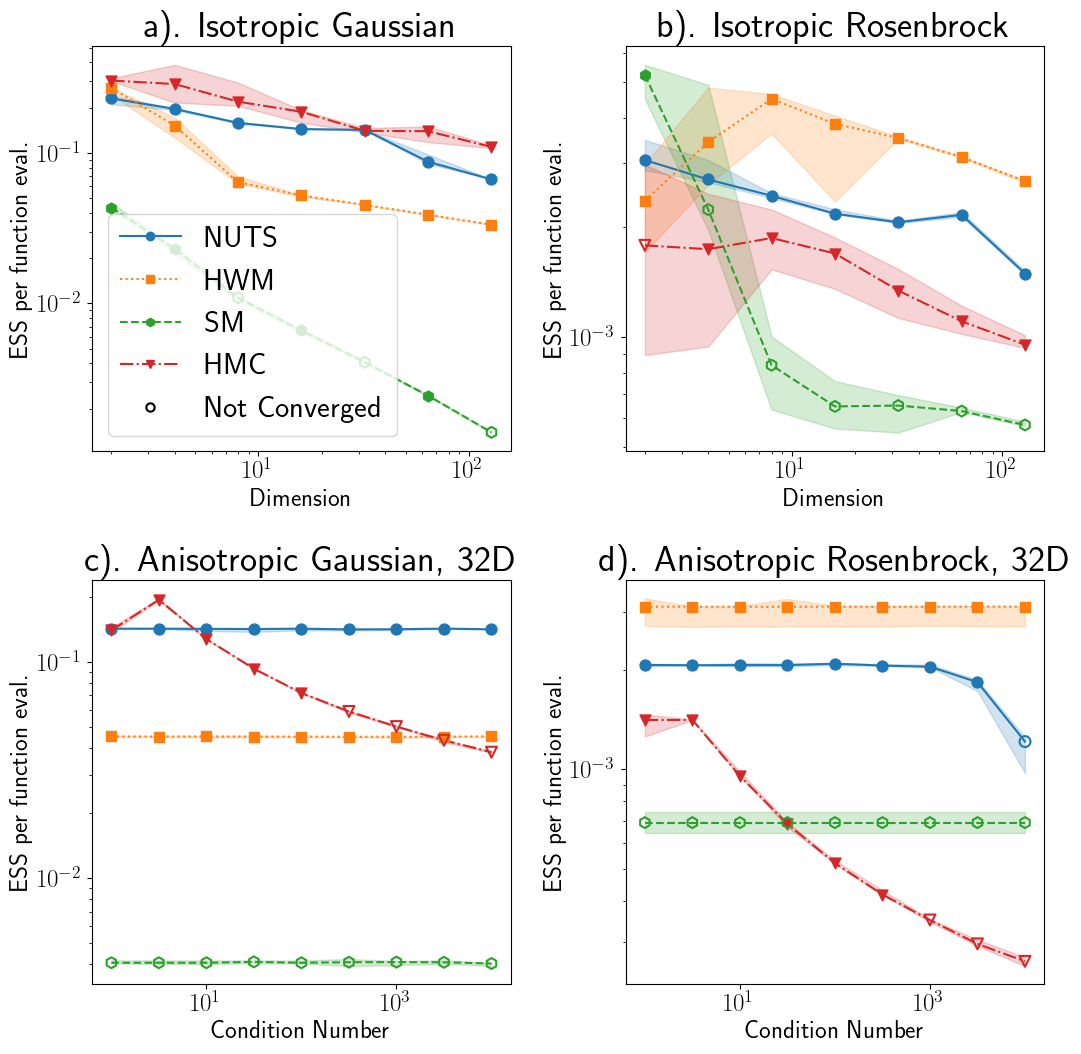

In [16]:
fig, ax = plt.subplots(2, 2, figsize = (11, 11))


plt.rcParams.update({'font.size': 22})

results_dims_g = np.load("GaussianResults/Gaussian_dimension_zipped_results.npz")
results_cond_g = np.load("GaussianResults/Gaussian_cond_zipped_results.npz")
results_cond_rb = np.load("RosenbrockResults/Rosenbrock_cond_zipped_results.npz")
results_dims_r = np.load("RosenbrockResults/Rosenbrock_dimension_zipped_results.npz")



#Constants:
dims = [2, 4, 8, 16, 32, 64, 128]
conds = [1, 3.162, 10, 31.62, 100, 316.2, 1000, 3162, 10000]
sampler_names = ['Dense-mass NUTS', 'Hamiltonian Walk Move', 'Stretch Move', 'HMC']
labels = dict(zip(sampler_names, ['NUTS', 'HWM', 'SM', 'HMC']))
styles = dict(zip(sampler_names, ['-', ':', '--', '-.']))
markers = dict(zip(sampler_names, ['o', 's', 'h', 'v']))
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = dict(zip(sampler_names, default_colors))


ESSpg_meds_cg = results_cond_g['ESS_med']
top_cg = results_cond_g['ESS_top']
bot_cg = results_cond_g['ESS_bot']

ESSpg_meds_cr = results_cond_rb['ESS_med']
top_cr = results_cond_rb['ESS_top']
bot_cr = results_cond_rb['ESS_bot']

ESSpg_meds_dg = results_dims_g['ESS_med']
top_dg = results_dims_g['ESS_top']
bot_dg = results_dims_g['ESS_bot']

ESSpg_meds_dr = results_dims_r['ESS_med']
top_dr = results_dims_r['ESS_top']
bot_dr = results_dims_r['ESS_bot']



for axes in ax.flatten():
    axes.set_yscale('log')
    axes.set_xscale('log')
    axes.set_ylabel('ESS per function eval.')

for values, top, bot, sampler in zip(ESSpg_meds_dg, top_dg, bot_dg, sampler_names):
    
    recovered = majority_parameter_recovery_mask(
        'GaussianResults/M', 'd', dims, sampler, 'Gaussian'
    )
    plot_sweep_series(
        ax[0,0], dims, values, recovered, marker=markers[sampler],
        color=colors[sampler], linestyle=styles[sampler]
    )
    ax[0,0].fill_between(dims, bot, top, color=colors[sampler], alpha=0.2)

for values, top, bot, sampler in zip(ESSpg_meds_dr, top_dr, bot_dr, sampler_names):
    recovered = majority_parameter_recovery_mask(
    "RosenbrockResults/dimension",
    "d",
    dims,
    sampler,
    "Paired Rosenbrock",
    )
    plot_sweep_series(
        ax[0,1], dims, values, recovered, marker=markers[sampler],
        color=colors[sampler], linestyle=styles[sampler]
    )
    ax[0,1].fill_between(dims, bot, top, color=colors[sampler], alpha=0.2)

for values, top, bot, sampler in zip(ESSpg_meds_cg, top_cg, bot_cg, sampler_names):
    recovered = majority_parameter_recovery_mask(
        'GaussianResults/C', 'c', conds, sampler, 'Gaussian'
    )
    plot_sweep_series(
        ax[1,0], conds, values, recovered, marker=markers[sampler],
        color=colors[sampler], linestyle=styles[sampler]
    )
    ax[1,0].fill_between(conds, bot, top, color=colors[sampler], alpha=0.2)

for values, top, bot, sampler in zip(ESSpg_meds_cr, top_cr, bot_cr, sampler_names):
    recovered = majority_parameter_recovery_mask(
        'RosenbrockResults/condition', 'c', conds, sampler, 'Paired Rosenbrock'
    )
    plot_sweep_series(
        ax[1,1], conds, values, recovered, marker=markers[sampler],
        color=colors[sampler], linestyle=styles[sampler]
    )
    ax[1,1].fill_between(conds, bot, top, color=colors[sampler], alpha=0.2)


ax[0,0].legend(handles=parameter_sweep_legend(
    sampler_names, [labels[name] for name in sampler_names], markers, styles, colors,
    failure_label=r'Not Converged'
))

ax[0,0].set_title('a). Isotropic Gaussian')
ax[0,1].set_title('b). Isotropic Rosenbrock')
ax[1,0].set_title('c). Anisotropic Gaussian, 32D')
ax[1,1].set_title('d). Anisotropic Rosenbrock, 32D')
ax[0,0].set_xlabel('Dimension')
ax[0,1].set_xlabel('Dimension')
ax[1,0].set_xlabel('Condition Number')
ax[1,1].set_xlabel('Condition Number')

fig.set_tight_layout('tight')
plt.savefig('performance.pdf', dpi = 200)

In [ ]:
from pathlib import Path
import json
import pandas as pd

def load_sweep(root, sweep, folder_suffix):
    """
    Function for loading parameter sweep results into arrays for plotting.
    Stores results within a Pandas Dataframe
    Arguments:
    ----------
    root : filename root containing the data
    sweep : parameter that is swept over (e.g. dimension, condition)
    folder_suffix : Results folder suffix
        "c" for root/16c
        "d" for root/4d
    
    """

    rows = [] # storage for 

    for parameter_dir in Path(root).iterdir(): #Iterate over the folders in the root directory
        if not parameter_dir.is_dir():
            continue #skip regular files that aren't folders (e.g. The LaTeX PDFs)
        if not parameter_dir.name.endswith(folder_suffix):
            continue #skip folders that don't pertain to our particular suffix.

        number = parameter_dir.name[:-len(folder_suffix)] #strip the number from the directory to use as a plot value
        axis_val = float(number) #cast as float for plotting

        for summary_path in parameter_dir.glob("seeds/seed_*/results_summary.json"): #inside the parameter dir, grab all of the seeds
            data = json.loads(summary_path.read_text()) #load json data
            seed = int(data['seed']) #grab seed number

            for sampler, result in data['summary'].items(): #iterate through the results from each sampler
                rows.append({ #append all of these dictionaries to the results list
                    'sweep':sweep, #sweep parameter
                    'distribution':result['distribution'],
                    'axis_value':axis_val, #sweep value
                    'seed':seed,
                    'sampler':sampler,
                    'mean_x1':result['parameter_mean'][0], #mean of first dimension parameter
                    'mean_x2':result['parameter_mean'][1], # mean of 2nd parameter
                    'variance_x1':result['parameter_variance'][0], #variance of 1st parameter
                    'variance_x2':result['parameter_variance'][1] #you get the idea
                })
    return pd.DataFrame(rows)


In [63]:
#loading the sweeps

condition_gaussian = load_sweep('GaussianResults/C', sweep = 'condition', folder_suffix='c')
condition_rosenbrock = load_sweep('RosenbrockResults/condition', sweep = 'condition', folder_suffix='c')

dimension_gaussian = load_sweep('GaussianResults/M', sweep = 'dimension', folder_suffix='d')
dimension_rosenbrock = load_sweep('RosenbrockResults/dimension', sweep = 'dimension', folder_suffix='d')

all_data = pd.concat([condition_gaussian, condition_rosenbrock, dimension_gaussian, dimension_rosenbrock], ignore_index=True)

all_data.to_csv('bingus.csv')


all_data = all_data.sort_values(by = ['sweep', 'axis_value', 'seed'])

print(all_data)


         sweep       distribution  axis_value  seed                sampler  \
176  condition           Gaussian         1.0     0        Dense-mass NUTS   
177  condition           Gaussian         1.0     0  Hamiltonian Walk Move   
178  condition           Gaussian         1.0     0           Stretch Move   
179  condition           Gaussian         1.0     0                    HMC   
356  condition  Paired Rosenbrock         1.0     0        Dense-mass NUTS   
..         ...                ...         ...   ...                    ...   
407  dimension           Gaussian       128.0     4                    HMC   
544  dimension  Paired Rosenbrock       128.0     4        Dense-mass NUTS   
545  dimension  Paired Rosenbrock       128.0     4  Hamiltonian Walk Move   
546  dimension  Paired Rosenbrock       128.0     4           Stretch Move   
547  dimension  Paired Rosenbrock       128.0     4                    HMC   

      mean_x1   mean_x2  variance_x1  variance_x2  
176  0.9943

In [64]:
plot_data = (
    all_data.groupby(['sweep', 'axis_value', 'sampler', 'distribution'], as_index=False)
    .agg(mean1_median=('mean_x1', 'median'),
         mean1_min=('mean_x1', 'min'),
         mean1_max=('mean_x1', 'max'),
         mean2_median=('mean_x2', 'median'),
         mean2_min=('mean_x2', 'min'),
         mean2_max=('mean_x2', 'max'),
         variance1_median=('variance_x1', 'median'),
         variance2_median=('variance_x2', 'median')
         )
)

In [90]:
# separating data for each plot
condition_sweep = plot_data[plot_data['sweep'] == 'condition']
dimension_sweep = plot_data[plot_data['sweep'] == 'dimension']

condition_rosenbrock = condition_sweep[condition_sweep['distribution'] == 'Paired Rosenbrock']
condition_gaussian = condition_sweep[condition_sweep['distribution'] == 'Gaussian']

dimension_rosenbrock = dimension_sweep[dimension_sweep['distribution'] == 'Paired Rosenbrock']
dimension_gaussian = dimension_sweep[dimension_sweep['distribution'] == 'Gaussian']


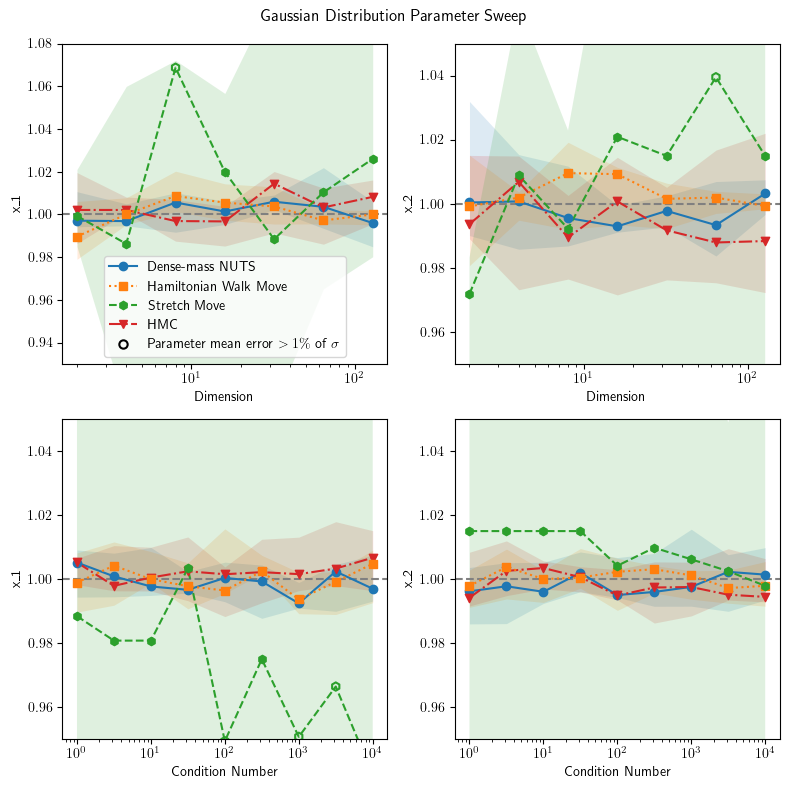

In [103]:
fig, ax = plt.subplots(2, 2, figsize = (8, 8))

#First plot, 1st parameter of Gaussian distribution, dimension sweep
linestyle = ['-', ':', '--', '-.']


markers = {"Dense-mass NUTS":'o', 'Hamiltonian Walk Move':'s', 'Stretch Move': 'h', 'HMC':'v'} #need to make a dictionary for this to work
styles = {"Dense-mass NUTS":"-", 'Hamiltonian Walk Move':':', 'Stretch Move':'--', 'HMC':'-.'}
seed_range_alpha = 0.15
default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
samplers = ['Dense-mass NUTS', 'Hamiltonian Walk Move', 'Stretch Move', 'HMC']
colors = dict(zip(samplers, default_colors))
fig.suptitle('Gaussian Distribution Parameter Sweep')

ax[0,0].set_ylim(0.93, 1.08)
ax[0,0].set_ylabel('x_1')
ax[0,0].set_xlabel('Dimension')
ax[0,1].set_xlabel('Dimension')
ax[1,0].set_ylabel('x_1')
ax[1,0].set_xlabel('Condition Number')
ax[1,1].set_xlabel('Condition Number')
ax[0,1].set_ylabel('x_2')
ax[1,1].set_ylabel('x_2')

ax[0,1].set_ylim(0.95, 1.05)
ax[1,1].set_ylim(0.95, 1.05)
ax[1,0].set_ylim(0.95, 1.05)


for axes in ax.flatten():
    axes.set_xscale('log')
    axes.axhline(1, color = 'gray', linestyle = '--')

for sampler, group in dimension_gaussian.groupby("sampler"):
    group = group.sort_values('axis_value')
    plot_sweep_series(
        ax[0,0], group['axis_value'], group['mean1_median'],
        single_parameter_recovery_mask(group['mean1_median'], 1.0, 3.16),
        marker=markers[sampler], color=colors[sampler],
        linestyle=styles[sampler]
    )
    ax[0,0].fill_between(
        group['axis_value'], group['mean1_min'], group['mean1_max'],
        color = colors[sampler], alpha = seed_range_alpha, linewidth = 0
    )
    plot_sweep_series(
        ax[0,1], group['axis_value'], group['mean2_median'],
        single_parameter_recovery_mask(group['mean2_median'], 1.0, 3.16),
        marker=markers[sampler], color=colors[sampler],
        linestyle=styles[sampler]
    )
    ax[0,1].fill_between(
        group['axis_value'], group['mean2_min'], group['mean2_max'],
        color = colors[sampler], alpha = seed_range_alpha, linewidth = 0
    )


for sampler, group in condition_gaussian.groupby("sampler"):
    group = group.sort_values('axis_value')
    plot_sweep_series(
        ax[1,0], group['axis_value'], group['mean1_median'],
        single_parameter_recovery_mask(group['mean1_median'], 1.0, 3.16),
        marker=markers[sampler], color=colors[sampler],
        linestyle=styles[sampler]
    )
    ax[1,0].fill_between(
        group['axis_value'], group['mean1_min'], group['mean1_max'],
        color = colors[sampler], alpha = seed_range_alpha, linewidth = 0
    )
    plot_sweep_series(
        ax[1,1], group['axis_value'], group['mean2_median'],
        single_parameter_recovery_mask(group['mean2_median'], 1.0, 3.16),
        marker=markers[sampler], color=colors[sampler],
        linestyle=styles[sampler]
    )
    ax[1,1].fill_between(
        group['axis_value'], group['mean2_min'], group['mean2_max'],
        color = colors[sampler], alpha = seed_range_alpha, linewidth = 0
    )


fig.set_tight_layout('tight')
ax[0,0].legend(handles=parameter_sweep_legend(
    samplers, samplers, markers, styles, colors,
    failure_label=r'Parameter mean error $>1\%$ of $\sigma$'
))

plt.savefig('Gaussian_parms.pdf', dpi = 200)

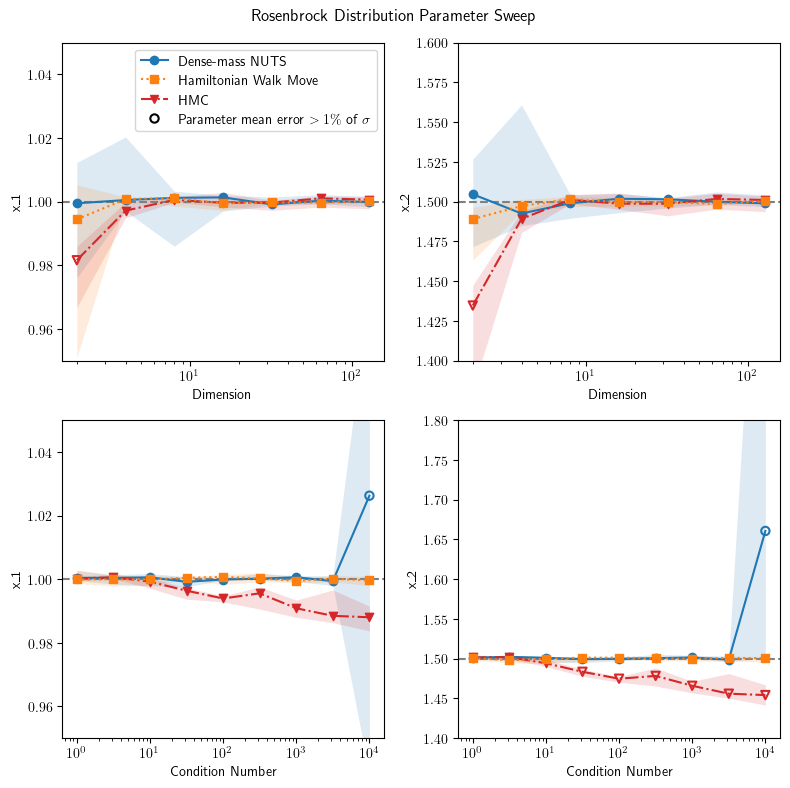

In [95]:
fig, ax = plt.subplots(2, 2, figsize = (8, 8))

#First plot, 1st parameter of Gaussian distribution, dimension sweep

markers = {"Dense-mass NUTS":'o', 'Hamiltonian Walk Move':'s', 'Stretch Move': 'h', 'HMC':'v'} #need to make a dictionary for this to work
styles = {"Dense-mass NUTS":"-", 'Hamiltonian Walk Move':':', 'Stretch Move':'--', 'HMC':'-.'}
default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
samplers = ['Dense-mass NUTS', 'Hamiltonian Walk Move', 'HMC']
colors = {'Dense-mass NUTS':default_colors[0], 'Hamiltonian Walk Move':default_colors[1], 'HMC':default_colors[3]}
fig.suptitle('Rosenbrock Distribution Parameter Sweep')
seed_range_alpha = 0.15


ax[0,0].set_ylabel('x_1')
ax[0,0].set_xlabel('Dimension')
ax[0,1].set_xlabel('Dimension')
ax[1,0].set_ylabel('x_1')
ax[1,0].set_xlabel('Condition Number')
ax[1,1].set_xlabel('Condition Number')
ax[0,1].set_ylabel('x_2')
ax[1,1].set_ylabel('x_2')

ax[0,0].axhline(1, color = 'gray', linestyle = '--')
ax[1,0].axhline(1, color = 'gray', linestyle = '--')
ax[0,1].axhline(1.5, color = 'gray', linestyle = '--')
ax[1,1].axhline(1.5, color = 'gray', linestyle = '--')

ax[0,0].set_ylim(0.95, 1.05)
ax[0,1].set_ylim(1.4, 1.6)
ax[1,1].set_ylim(1.4, 1.8)
ax[1,0].set_ylim(0.95, 1.05)

for axes in ax.flatten():
    axes.set_xscale('log')

for sampler, group in dimension_rosenbrock.groupby("sampler"):
    group = group.sort_values('axis_value')
    if sampler == "Stretch Move": 
        continue

    plot_sweep_series(
        ax[0,0], group['axis_value'], group['mean1_median'],
        single_parameter_recovery_mask(group['mean1_median'], 1.0, 1.5),
        marker=markers[sampler], color=colors[sampler],
        linestyle=styles[sampler]
    )
    ax[0,0].fill_between(
        group['axis_value'], group['mean1_min'], group['mean1_max'],
        color = colors[sampler], alpha = seed_range_alpha, linewidth = 0
    )
    plot_sweep_series(
        ax[0,1], group['axis_value'], group['mean2_median'],
        single_parameter_recovery_mask(
            group['mean2_median'], 1.5, np.sqrt(2.502)
        ),
        marker=markers[sampler], color=colors[sampler],
        linestyle=styles[sampler]
    )
    ax[0,1].fill_between(
        group['axis_value'], group['mean2_min'], group['mean2_max'],
        color = colors[sampler], alpha = seed_range_alpha, linewidth = 0
    )

for sampler, group in condition_rosenbrock.groupby("sampler"):
    if sampler == "Stretch Move":
        continue
    group = group.sort_values('axis_value')
    plot_sweep_series(
        ax[1,0], group['axis_value'], group['mean1_median'],
        single_parameter_recovery_mask(group['mean1_median'], 1.0, 1.5),
        marker=markers[sampler], color=colors[sampler],
        linestyle=styles[sampler]
    )
    ax[1,0].fill_between(
        group['axis_value'], group['mean1_min'], group['mean1_max'],
        color = colors[sampler], alpha = seed_range_alpha, linewidth = 0
    )
    plot_sweep_series(
        ax[1,1], group['axis_value'], group['mean2_median'],
        single_parameter_recovery_mask(
            group['mean2_median'], 1.5, np.sqrt(2.502)
        ),
        marker=markers[sampler], color=colors[sampler],
        linestyle=styles[sampler]
    )
    ax[1,1].fill_between(
        group['axis_value'], group['mean2_min'], group['mean2_max'],
        color = colors[sampler], alpha = seed_range_alpha, linewidth = 0
    )


fig.set_tight_layout('tight')
ax[0,0].legend(handles=parameter_sweep_legend(
    samplers, samplers, markers, styles, colors,
    failure_label=r'Parameter mean error $>1\%$ of $\sigma$'
))

plt.savefig('Rb_parms.pdf', dpi = 200)

Text(0.5, 1.0, 'Anisotropic Rosenbrock, 32D')

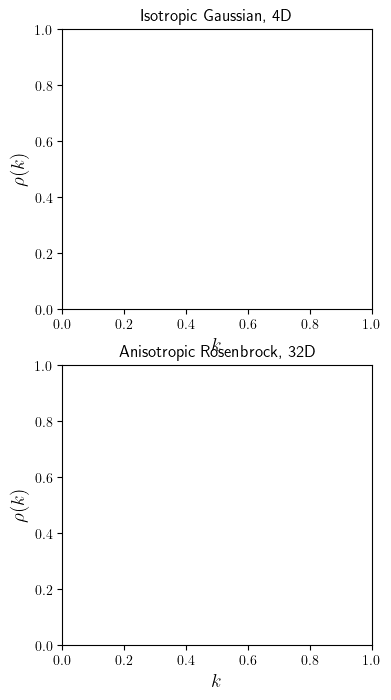

In [59]:
#example autocorrelation plots

fig, ax = plt.subplots(2, 1, figsize = (4, 8))

axf = ax.flatten()

axf[0].set_ylabel(r'$\rho(k)$', fontsize = 14)
axf[1].set_ylabel(r'$\rho(k)$', fontsize = 14)
axf[0].set_xlabel(r'$k$', fontsize = 14)
axf[1].set_xlabel(r'$k$', fontsize = 14)
axf[0].set_title(r'Isotropic Gaussian, 4D')
axf[1].set_title(r'Anisotropic Rosenbrock, 32D')